# 📩 Message Intelligence System
### Spam vs Legitimate Message Classification using KNN, SVM & Naive Bayes
**Duration:** 6 Hours  |  **Role:** Data Scientist – Communication Security Company

**Target:** `spam_label` → `0` = Legitimate, `1` = Spam

**Notebook roadmap:** Part A Theory → B Data prep → C KNN → D SVM → E Naive Bayes & Bayes' theorem → F Model comparison → G Final report

In [1]:
import os, warnings, time, pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc,
                             classification_report)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
os.makedirs("charts", exist_ok=True); os.makedirs("models", exist_ok=True)

def savefig(name):
    plt.savefig(f"charts/{name}.png", dpi=130, bbox_inches="tight")

def evaluate(y_true, y_pred):
    return dict(Accuracy=accuracy_score(y_true, y_pred),
                Precision=precision_score(y_true, y_pred, zero_division=0),
                Recall=recall_score(y_true, y_pred),
                F1=f1_score(y_true, y_pred))
print("Libraries loaded ✔")

Libraries loaded ✔


---
## 🧠 Part A: Probability & Conceptual Foundation (Theory)

**1. What is Conditional Probability?**
Conditional probability is the probability of an event **A** happening *given that* another event **B** has already occurred:
$P(A\mid B)=\dfrac{P(A\cap B)}{P(B)},\; P(B)>0$.
Example: P(Spam | message contains a URL) – among only the messages that contain a URL, what fraction are spam. It lets us update our belief about a message once we observe evidence.

**2. Bayes' Theorem and its importance in classification**
$P(C\mid X)=\dfrac{P(X\mid C)\,P(C)}{P(X)}$ — *posterior = likelihood × prior / evidence.*
For classification we compute the posterior for every class (Spam / Legit) given the message features and predict the class with the highest posterior. It is important because it (a) combines prior class frequencies with evidence from features, (b) outputs real probabilities (useful for risk-based decisions and thresholds), and (c) works well with little data. It is the foundation of Naive Bayes.

**3. Assumptions of the Naive Bayes Classifier**
(i) **Conditional independence** – given the class, all features are independent: $P(X\mid C)=\prod_i P(x_i\mid C)$. (ii) Every feature contributes **equally and independently** to the outcome. (iii) A **distribution assumption** for each feature (Gaussian for continuous – GaussianNB, Bernoulli for binary, Multinomial for counts). (iv) Training data is representative of the class priors. Real features such as `message_length` and `word_count` are correlated, so (i) is only approximately true – yet NB often still works.

**4. Working principle**
- **K-Nearest Neighbors (KNN):** a *lazy*, instance-based learner – it stores the training data. For a new message it measures the distance (Euclidean, Manhattan …) to all training points, picks the **K closest** and predicts the **majority class** among them. Needs feature scaling; small K → low bias/high variance, large K → smoother boundary.
- **Support Vector Machine (SVM):** finds the **hyperplane that maximises the margin** between the two classes. Only the closest points (**support vectors**) define it. The soft-margin parameter **C** trades margin width against misclassification; **kernels** (linear, RBF, polynomial) let SVM learn non-linear boundaries by implicitly mapping data to a higher-dimensional space.

**5. Distance-based vs Probabilistic vs Margin-based classifiers**

| Aspect | Distance-based (KNN) | Probabilistic (Naive Bayes) | Margin-based (SVM) |
|---|---|---|---|
| Core idea | Similar points → same class | Highest posterior P(C\|X) | Maximum-margin boundary |
| Training | None (lazy) | Very fast (counts/means) | Optimisation (slower) |
| Prediction cost | High (scan all data) | Very low | Low (support vectors only) |
| Needs scaling | Yes (critical) | Not strictly | Yes (critical) |
| Output | Class / neighbour vote | Calibrated-ish probabilities | Distance to boundary (score) |
| Key assumption | Local neighbourhood is meaningful | Feature independence | Classes separable with margin/kernel |
| Interpretability | Medium (show neighbours) | High (probabilities per feature) | Low (esp. non-linear kernels) |

---
## 🧪 Part B: Dataset Understanding & Preparation

In [2]:
df = pd.read_csv("data/Message_Intelligence_Dataset_5200.csv")
print("Shape:", df.shape)
display(df.head())
print("\nData types & missing values:")
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "missing_%": (df.isna().mean()*100).round(2)}))

Shape: (5200, 16)

Data types & missing values:


,message_id,message_text,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,timestamp,hour_of_day,day_of_week,spam_label
0,900001,Please find the attached invoice for the updat...,99,11,1,4,0,0,1,56.6,500.0,6.0,2025-11-24 02:00:00,2,0,0
1,900002,Let's catch up tomorrow regarding the timeline...,73,12,0,0,0,0,0,16.6,207.0,0.0,2025-12-17 21:00:00,21,2,0
2,900003,Can you send the report by end of day? next Mo...,67,13,0,0,0,0,1,25.7,418.0,6.0,2025-11-15 13:00:00,13,5,0
3,900004,Can you send the report by end of day? 10:30 A...,64,13,0,4,0,0,1,48.8,276.0,5.0,2025-12-17 23:00:00,23,2,0
4,900005,Could you review the document and share feedba...,84,14,0,0,0,0,1,33.0,683.0,7.0,2025-11-29 11:00:00,11,5,0


,dtype,missing,missing_%
message_id,int64,0,0.00
message_text,str,0,0.00
message_length,int64,0,0.00
word_count,int64,0,0.00
num_urls,int64,0,0.00
num_digits,int64,0,0.00
num_special_chars,int64,0,0.00
spam_keyword_score,int64,0,0.00
legit_keyword_score,int64,0,0.00
sender_activity_score,float64,106,2.04


spam_label
0    4227
1     973
Name: count, dtype: int64 
Spam share: 18.7%


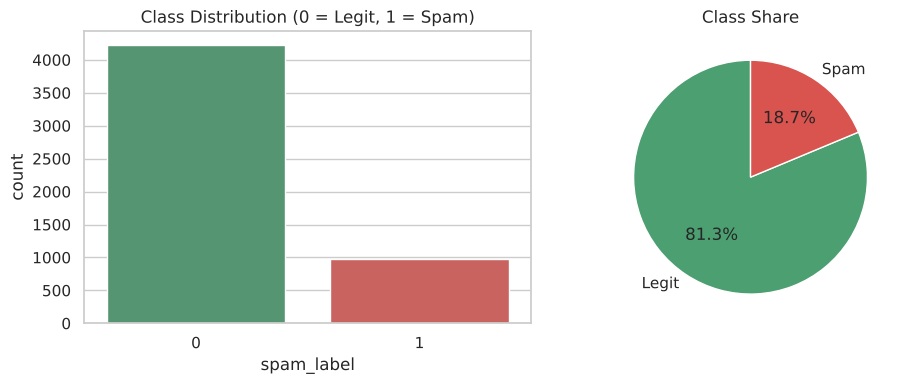

In [3]:
# Target distribution
counts = df["spam_label"].value_counts().sort_index()
print(counts, "\nSpam share: %.1f%%" % (counts[1]/len(df)*100))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x="spam_label", data=df, palette=["#4C9F70", "#D9534F"], ax=ax[0])
ax[0].set_title("Class Distribution (0 = Legit, 1 = Spam)"); ax[0].set_xlabel("spam_label")
ax[1].pie(counts, labels=["Legit", "Spam"], autopct="%.1f%%", colors=["#4C9F70", "#D9534F"], startangle=90)
ax[1].set_title("Class Share"); plt.tight_layout(); savefig("01_class_distribution"); plt.show()

**Interpretation:** the data is **imbalanced** (~81% legit vs ~19% spam). Accuracy alone can be misleading, so Precision, Recall and F1 on the spam class are the key metrics. We use a *stratified* split so both sets keep the same ratio.

In [4]:
# ---- Task 6: Input features and target ----
TARGET = "spam_label"
DROP = ["message_id", "message_text", "timestamp"]   # identifier / raw text / raw datetime (time features already extracted)
FEATURES = [c for c in df.columns if c not in DROP + [TARGET]]
print("Input features (%d):" % len(FEATURES)); print(FEATURES); print("Target:", TARGET)
df[FEATURES + [TARGET]].describe().T.round(2)

Input features (12):
['message_length', 'word_count', 'num_urls', 'num_digits', 'num_special_chars', 'spam_keyword_score', 'legit_keyword_score', 'sender_activity_score', 'sender_account_age_days', 'messages_sent_last_24h', 'hour_of_day', 'day_of_week']
Target: spam_label


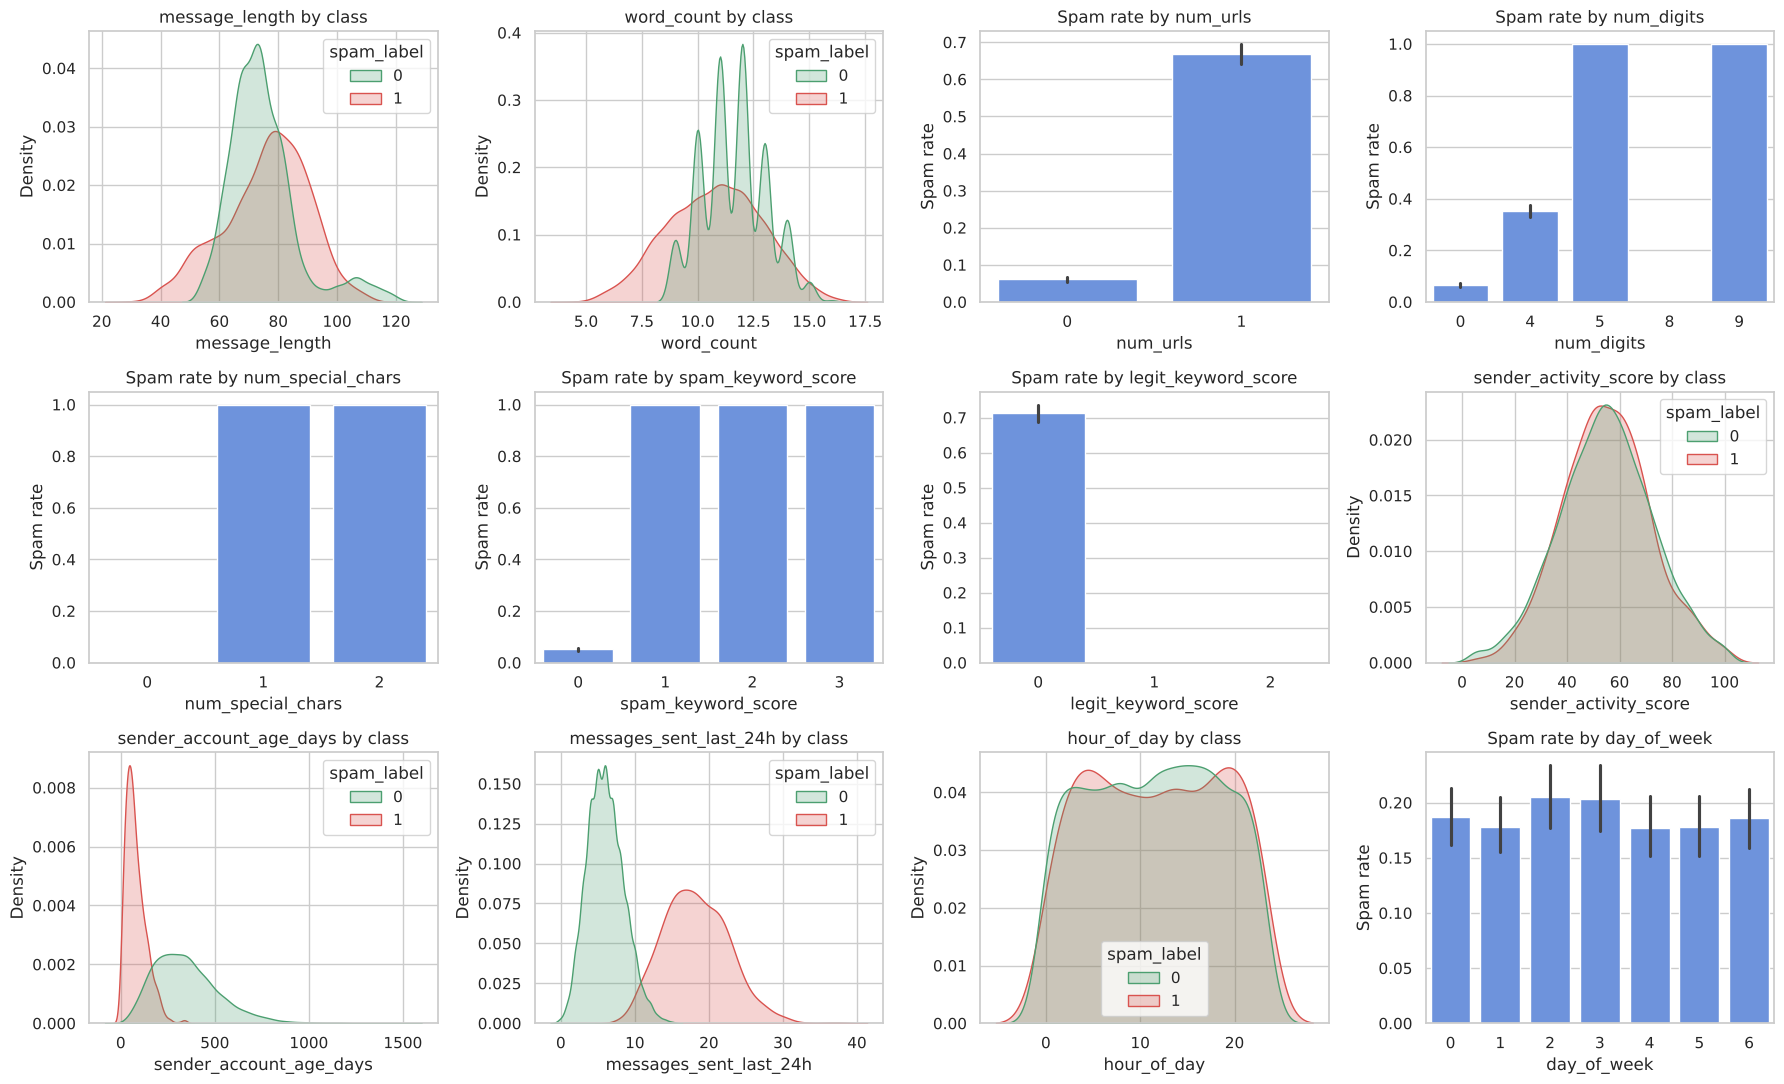

In [5]:
# EDA: feature behaviour by class
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.ravel(), FEATURES):
    if df[col].nunique() <= 10:
        sns.barplot(x=col, y=TARGET, data=df, ax=ax, color="#5B8DEF"); ax.set_ylabel("Spam rate")
        ax.set_title(f"Spam rate by {col}")
    else:
        sns.kdeplot(data=df, x=col, hue=TARGET, common_norm=False, fill=True, palette=["#4C9F70", "#D9534F"], ax=ax)
        ax.set_title(f"{col} by class")
plt.tight_layout(); savefig("02_feature_vs_class"); plt.show()

**Interpretation:** spam messages show far more URLs, digits and special characters, a non-zero `spam_keyword_score`, much younger sender accounts (~80 vs ~350 days) and many more messages in the last 24 h (~18 vs ~6); legit messages carry `legit_keyword_score` > 0. In contrast `message_length`, `sender_activity_score`, `hour_of_day` and `day_of_week` look almost identical for both classes (weak signals).

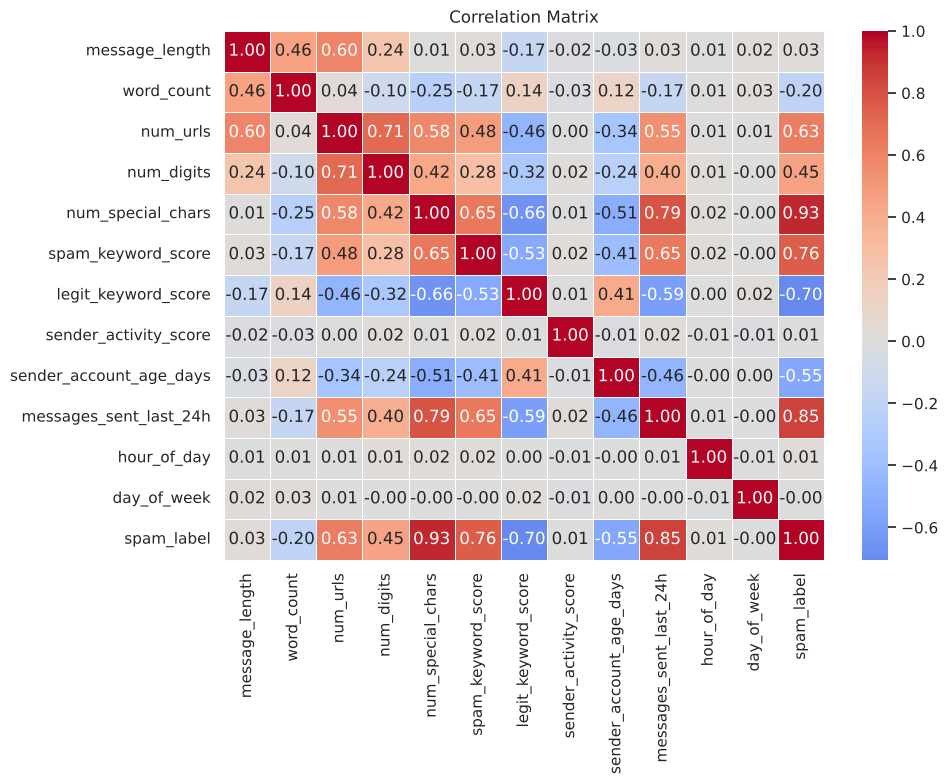

In [6]:
# Correlation heat-map (multicollinearity matters for Naive Bayes' independence assumption)
plt.figure(figsize=(10, 8))
sns.heatmap(df[FEATURES + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.4)
plt.title("Correlation Matrix"); plt.tight_layout(); savefig("03_correlation"); plt.show()

**Interpretation:** several features are correlated (e.g. `message_length`–`word_count`, `num_urls`–`num_digits`, and the keyword scores with the label) – this **violates the independence assumption** of Naive Bayes; we test its impact in Part E.

In [7]:
# ---- Task 8: Train / test split (stratified 80/20) – split BEFORE fitting any transformer to avoid leakage ----
X = df[FEATURES]; y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Spam rate  train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

# ---- Task 7: Preprocessing – median imputation (missing values) + StandardScaler (needed for KNN/SVM) ----
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
X_train_s = scaler.fit_transform(imputer.fit_transform(X_train))
X_test_s  = scaler.transform(imputer.transform(X_test))
print("Missing after imputation:", np.isnan(X_train_s).sum(), "| train mean≈%.2f, std≈%.2f" % (X_train_s.mean(), X_train_s.std()))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: (4160, 12)  Test: (1040, 12)
Spam rate  train: 0.187 | test: 0.188
Missing after imputation: 0 | train mean≈-0.00, std≈1.00


**Preprocessing summary:** (1) identifier/text/raw timestamp dropped, (2) missing values in 3 behaviour features filled with the **training median**, (3) all features **standardised** (distance & margin models are scale-sensitive), (4) imputer/scaler were **fitted on training data only** → no data leakage.

---
## 📊 Part C: Baseline Model – K-Nearest Neighbors

In [8]:
# ---- Task 9: baseline KNN (K=5, Euclidean) ----
knn_base = KNeighborsClassifier(n_neighbors=5, metric="euclidean").fit(X_train_s, y_train)
pred = knn_base.predict(X_test_s)
print("Baseline KNN (K=5, euclidean):", {k: round(v, 4) for k, v in evaluate(y_test, pred).items()})
print(classification_report(y_test, pred, target_names=["Legit", "Spam"]))

Baseline KNN (K=5, euclidean): {'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0}
              precision    recall  f1-score   support

       Legit       1.00      1.00      1.00       845
        Spam       1.00      1.00      1.00       195

    accuracy                           1.00      1040
   macro avg       1.00      1.00      1.00      1040
weighted avg       1.00      1.00      1.00      1040



Best K by cross-validation: 1


,K,Train_F1,CV_F1,Test_Acc,Test_F1
0,1,1.0000,1.0000,1.000,1.0000
1,3,1.0000,0.9994,1.000,1.0000
2,5,1.0000,0.9994,1.000,1.0000
3,7,1.0000,0.9994,0.999,0.9974
4,9,0.9994,0.9994,0.999,0.9974
5,11,0.9994,0.9987,0.999,0.9974
6,13,0.9994,0.9987,0.999,0.9974
7,15,0.9994,0.9987,0.999,0.9974
8,17,0.9994,0.9981,0.999,0.9974
9,19,0.9987,0.9981,0.999,0.9974


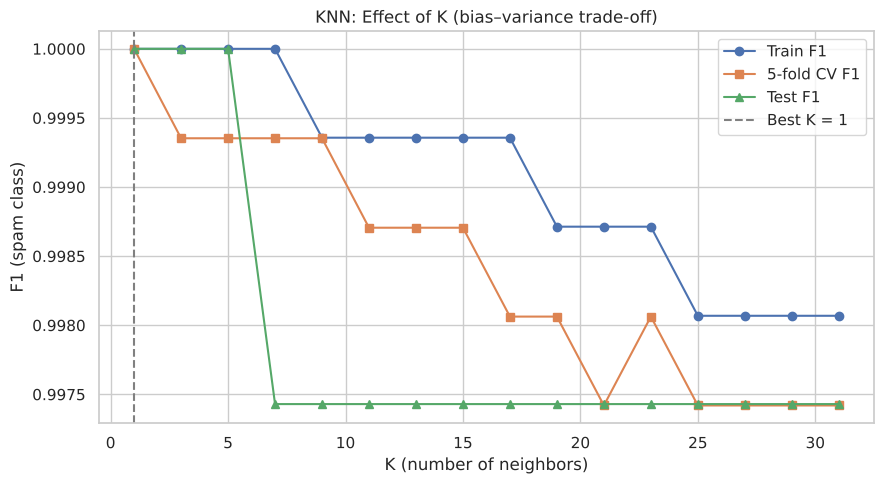

In [9]:
# ---- Task 10: different values of K (selected using 5-fold CV on TRAIN set only) ----
ks = list(range(1, 32, 2)); rows = []
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
    cvf1 = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_s, y_train, cv=cv, scoring="f1").mean()
    rows.append(dict(K=k, Train_F1=f1_score(y_train, m.predict(X_train_s)), CV_F1=cvf1,
                     Test_Acc=accuracy_score(y_test, m.predict(X_test_s)), Test_F1=f1_score(y_test, m.predict(X_test_s))))
k_df = pd.DataFrame(rows); BEST_K = int(k_df.sort_values(["CV_F1", "K"], ascending=[False, False]).iloc[0]["K"])  # ties -> larger K (smoother, less overfit)
display(k_df.round(4))
plt.figure(figsize=(9, 5))
plt.plot(k_df.K, k_df.Train_F1, "o-", label="Train F1"); plt.plot(k_df.K, k_df.CV_F1, "s-", label="5-fold CV F1")
plt.plot(k_df.K, k_df.Test_F1, "^-", label="Test F1"); plt.axvline(BEST_K, ls="--", c="gray", label=f"Best K = {BEST_K}")
plt.xlabel("K (number of neighbors)"); plt.ylabel("F1 (spam class)"); plt.title("KNN: Effect of K (bias–variance trade-off)")
plt.legend(); plt.tight_layout(); savefig("04_knn_k_sweep"); plt.show()
print("Best K by cross-validation:", BEST_K)

**Interpretation:** because this data is (almost) perfectly separable, all K values score ≈ 99.7–100% and the curves for Train / CV / Test overlap – even K=1 does not overfit here. The F1 still drops slowly as K grows, because with a large K the minority spam class gets **out-voted** by the majority legit neighbours (underfitting / high bias). K is chosen by **cross-validation** on the training set, never on the test set. On the harder Scenario B (Part F+) the CV-selected K is larger (K=3), showing the usual bias–variance trade-off.

KNN WITHOUT scaling  F1=0.9259 | WITH scaling F1=1.0000


,Accuracy,Precision,Recall,F1
Distance,,,,
euclidean (L2),1.000,1.0,1.0000,1.0000
manhattan (L1),1.000,1.0,1.0000,1.0000
chebyshev (L∞),0.999,1.0,0.9949,0.9974
minkowski p=3,1.000,1.0,1.0000,1.0000
cosine,1.000,1.0,1.0000,1.0000


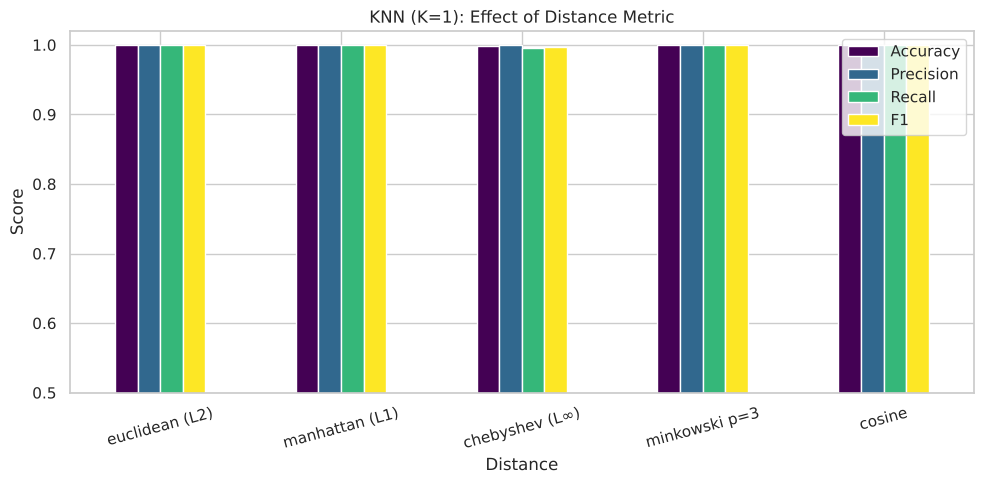

In [10]:
# ---- Task 11: effect of distance metrics ----
metrics = {"euclidean (L2)": dict(metric="euclidean"), "manhattan (L1)": dict(metric="manhattan"),
           "chebyshev (L∞)": dict(metric="chebyshev"), "minkowski p=3": dict(metric="minkowski", p=3),
           "cosine": dict(metric="cosine", algorithm="brute")}
res = []
for name, kw in metrics.items():
    m = KNeighborsClassifier(n_neighbors=BEST_K, **kw).fit(X_train_s, y_train)
    r = evaluate(y_test, m.predict(X_test_s)); r["Distance"] = name; res.append(r)
dist_df = pd.DataFrame(res).set_index("Distance"); display(dist_df.round(4))
dist_df.plot(kind="bar", figsize=(10, 5), rot=15, colormap="viridis"); plt.ylim(0.5, 1.02)
plt.title(f"KNN (K={BEST_K}): Effect of Distance Metric"); plt.ylabel("Score"); plt.tight_layout(); savefig("05_knn_distance_metrics"); plt.show()

# effect of scaling (why preprocessing matters for distance-based models)
raw_med = X_train.fillna(X_train.median()); raw_te = X_test.fillna(X_train.median())
m_raw = KNeighborsClassifier(n_neighbors=BEST_K).fit(raw_med, y_train)
print("KNN WITHOUT scaling  F1=%.4f | WITH scaling F1=%.4f" % (f1_score(y_test, m_raw.predict(raw_te)),
      f1_score(y_test, KNeighborsClassifier(n_neighbors=BEST_K).fit(X_train_s, y_train).predict(X_test_s))))

**Interpretation:** different metrics weigh feature differences differently – Manhattan is less sensitive to a single large deviation, Chebyshev only looks at the largest single-feature gap, Euclidean squares differences. The table above shows which suits this data best. Also note the large drop **without scaling**: `sender_account_age_days` (up to 1500) would dominate every distance calculation.

In [11]:
# Final tuned KNN used in the rest of the notebook
best_metric = dist_df["F1"].idxmax()
knn = KNeighborsClassifier(n_neighbors=BEST_K, **metrics[best_metric]).fit(X_train_s, y_train)
knn_pred = knn.predict(X_test_s); knn_proba = knn.predict_proba(X_test_s)[:, 1]
print(f"Final KNN → K={BEST_K}, metric={best_metric}:", {k: round(v, 4) for k, v in evaluate(y_test, knn_pred).items()})

# ---- Task 12: where does KNN misclassify? ----
test_df = df.loc[X_test.index].copy(); test_df["knn_pred"] = knn_pred
fp = test_df[(test_df.spam_label == 0) & (test_df.knn_pred == 1)]
fn = test_df[(test_df.spam_label == 1) & (test_df.knn_pred == 0)]
print(f"False Positives (legit flagged as spam): {len(fp)} | False Negatives (spam missed): {len(fn)}")
cols = ["message_text", "num_urls", "spam_keyword_score", "legit_keyword_score", "sender_activity_score", "sender_account_age_days", "messages_sent_last_24h"]
pd.set_option("display.max_colwidth", 90)
print("\n--- Spam messages missed by KNN (False Negatives) ---"); display(fn[cols].head(8))
print("--- Legit messages blocked by KNN (False Positives) ---"); display(fp[cols].head(8))

Final KNN → K=1, metric=euclidean (L2): {'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0}
False Positives (legit flagged as spam): 0 | False Negatives (spam missed): 0

--- Spam messages missed by KNN (False Negatives) ---
--- Legit messages blocked by KNN (False Positives) ---


,message_text,num_urls,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h


,message_text,num_urls,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h


,Missed spam (FN),Caught spam (TP),Legit blocked (FP),Correct legit (TN)
message_length,NaN,74.03,NaN,75.09
word_count,NaN,10.63,NaN,11.62
num_urls,NaN,0.72,NaN,0.10
num_digits,NaN,4.03,NaN,1.23
num_special_chars,NaN,1.29,NaN,0.00
spam_keyword_score,NaN,1.22,NaN,0.00
legit_keyword_score,NaN,0.00,NaN,0.99
sender_activity_score,NaN,59.19,NaN,54.17
sender_account_age_days,NaN,75.81,NaN,357.32
messages_sent_last_24h,NaN,18.63,NaN,5.95


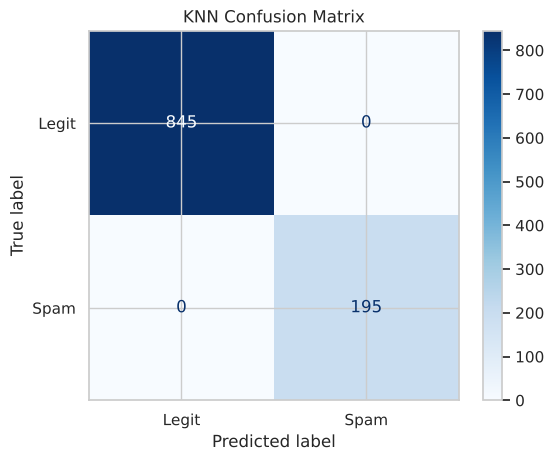

In [12]:
# Profile of the errors vs correct predictions
prof = pd.DataFrame({"Missed spam (FN)": fn[FEATURES].mean(), "Caught spam (TP)": test_df[(test_df.spam_label==1)&(test_df.knn_pred==1)][FEATURES].mean(),
                     "Legit blocked (FP)": fp[FEATURES].mean(), "Correct legit (TN)": test_df[(test_df.spam_label==0)&(test_df.knn_pred==0)][FEATURES].mean()}).round(2)
display(prof)
ConfusionMatrixDisplay(confusion_matrix(y_test, knn_pred), display_labels=["Legit", "Spam"]).plot(cmap="Blues"); plt.title("KNN Confusion Matrix")
savefig("06_knn_confusion"); plt.show()

**Misclassification analysis (KNN):** with all 12 features KNN makes **zero errors** on this test set (the dataset is perfectly separable – see the leakage check in Part F+), so there is nothing to inspect here. The error analysis on the realistic *Scenario B* feature set is done at the end of Part F+, where KNN does make mistakes.

---
## 🧩 Part D: Support Vector Machine Classifier

In [13]:
# ---- Task 13: SVM with Linear, RBF and Polynomial kernels ----
svm_models = {"Linear": SVC(kernel="linear", C=1, probability=True, random_state=RANDOM_STATE),
              "RBF": SVC(kernel="rbf", C=1, gamma="scale", probability=True, random_state=RANDOM_STATE),
              "Polynomial (deg 3)": SVC(kernel="poly", degree=3, C=1, gamma="scale", probability=True, random_state=RANDOM_STATE)}
rows = []
for name, m in svm_models.items():
    t = time.time(); m.fit(X_train_s, y_train); p = m.predict(X_test_s)
    r = evaluate(y_test, p); r.update(Kernel=name, Support_Vectors=int(m.n_support_.sum()), Fit_sec=round(time.time()-t, 2)); rows.append(r)
svm_kernel_df = pd.DataFrame(rows).set_index("Kernel"); display(svm_kernel_df.round(4))

,Accuracy,Precision,Recall,F1,Support_Vectors,Fit_sec
Kernel,,,,,,
Linear,1.0,1.0,1.0,1.0,10,0.07
RBF,1.0,1.0,1.0,1.0,139,0.22
Polynomial (deg 3),1.0,1.0,1.0,1.0,67,0.12


In [14]:
# Tune RBF SVM (C, gamma) with 5-fold CV on the training set
grid = GridSearchCV(SVC(kernel="rbf"), {"C": [0.1, 1, 10, 100], "gamma": ["scale", 0.01, 0.05, 0.1]}, cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_train_s, y_train)
print("Best RBF params:", grid.best_params_, "| CV F1 = %.4f" % grid.best_score_)
svm = SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE, **grid.best_params_).fit(X_train_s, y_train)
svm_pred = svm.predict(X_test_s); svm_score = svm.decision_function(X_test_s)
print("Tuned RBF SVM:", {k: round(v, 4) for k, v in evaluate(y_test, svm_pred).items()})

Best RBF params: {'C': 0.1, 'gamma': 'scale'} | CV F1 = 1.0000
Tuned RBF SVM: {'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0}


Linear SVM geometric margin width = 2/||w|| = 1.891 (in standardised units)


,C,Margin_width,Support_Vectors,Test_F1
0,0.01,2.3820,82,1.0
1,0.10,1.9604,18,1.0
2,1.00,1.8913,10,1.0
3,10.00,1.8913,10,1.0
4,100.00,1.8913,10,1.0


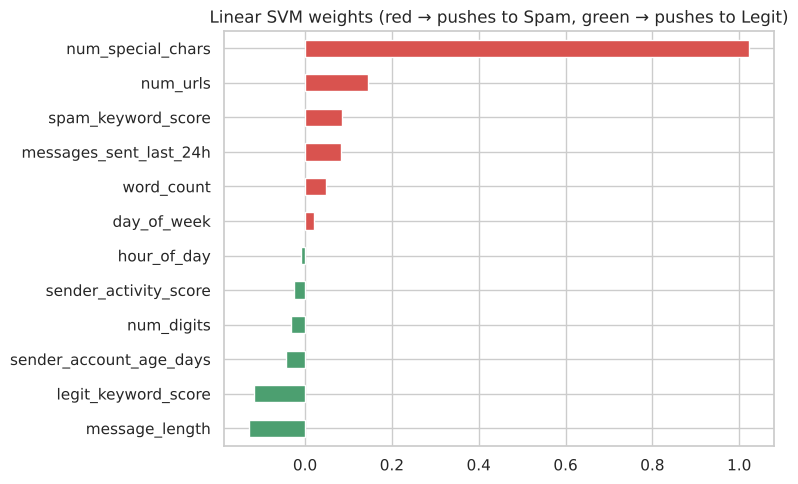

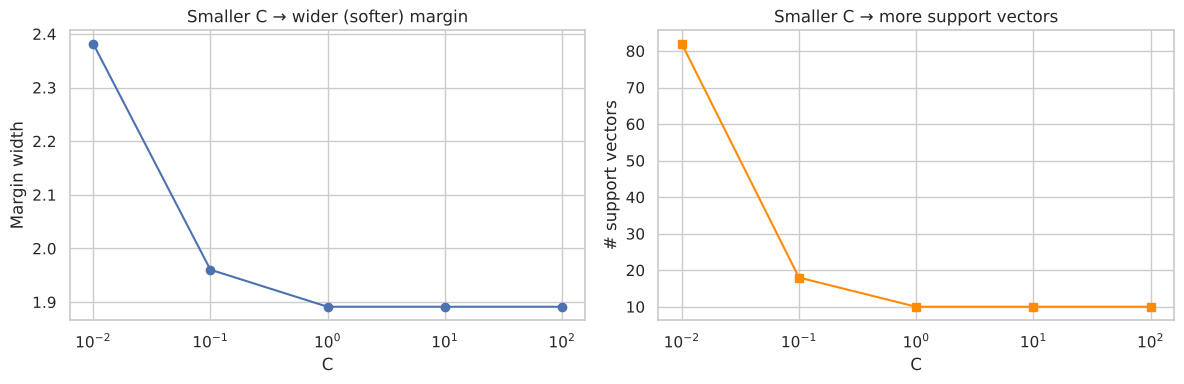

In [15]:
# ---- Task 14: margin separation & support vectors ----
lin = svm_models["Linear"]
w = lin.coef_[0]; print("Linear SVM geometric margin width = 2/||w|| = %.3f (in standardised units)" % (2/np.linalg.norm(w)))
coef = pd.Series(w, index=FEATURES).sort_values()
plt.figure(figsize=(8, 5)); coef.plot(kind="barh", color=np.where(coef > 0, "#D9534F", "#4C9F70"))
plt.title("Linear SVM weights (red → pushes to Spam, green → pushes to Legit)"); plt.tight_layout(); savefig("07_svm_linear_weights"); plt.show()

# effect of C on margin & number of support vectors
rows = []
for C in [0.01, 0.1, 1, 10, 100]:
    m = SVC(kernel="linear", C=C).fit(X_train_s, y_train)
    rows.append(dict(C=C, Margin_width=2/np.linalg.norm(m.coef_[0]), Support_Vectors=int(m.n_support_.sum()),
                     Test_F1=f1_score(y_test, m.predict(X_test_s))))
c_df = pd.DataFrame(rows); display(c_df.round(4))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogx(c_df.C, c_df.Margin_width, "o-"); ax[0].set_title("Smaller C → wider (softer) margin"); ax[0].set_xlabel("C"); ax[0].set_ylabel("Margin width")
ax[1].semilogx(c_df.C, c_df.Support_Vectors, "s-", c="darkorange"); ax[1].set_title("Smaller C → more support vectors"); ax[1].set_xlabel("C"); ax[1].set_ylabel("# support vectors")
plt.tight_layout(); savefig("08_svm_C_effect"); plt.show()

Explained variance by 2 PCs: 48.8%


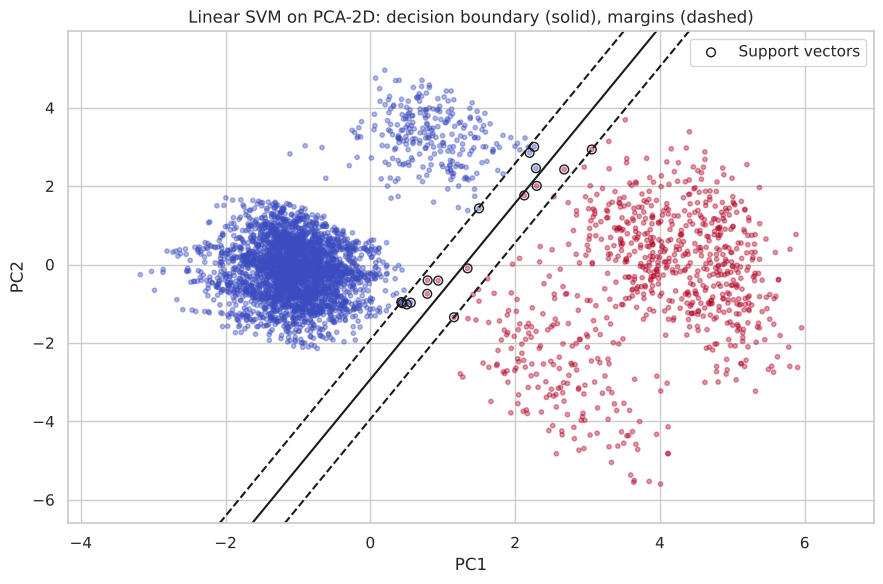

In [16]:
# 2-D visualisation of margin, boundary & support vectors (PCA projection – illustration only)
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_train_s)
Z = pca.transform(X_train_s); vis = SVC(kernel="linear", C=1).fit(Z, y_train)
xx, yy = np.meshgrid(np.linspace(Z[:,0].min()-1, Z[:,0].max()+1, 300), np.linspace(Z[:,1].min()-1, Z[:,1].max()+1, 300))
dec = vis.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.figure(figsize=(9, 6))
plt.scatter(Z[:,0], Z[:,1], c=y_train, cmap="coolwarm", s=10, alpha=.4)
plt.contour(xx, yy, dec, levels=[-1, 0, 1], colors=["k", "k", "k"], linestyles=["--", "-", "--"])
plt.scatter(*vis.support_vectors_.T, s=40, facecolors="none", edgecolors="k", label="Support vectors")
plt.title("Linear SVM on PCA-2D: decision boundary (solid), margins (dashed)"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend()
plt.tight_layout(); savefig("09_svm_margin_pca"); plt.show()
print("Explained variance by 2 PCs: %.1f%%" % (pca.explained_variance_ratio_.sum()*100))

**Interpretation (margin & support vectors):** only the **support vectors** (circled) lie on or inside the margin and define the boundary – all other points could be removed without changing the model. A **small C** tolerates more margin violations → wider margin, more support vectors, smoother/simpler model; a **large C** penalises errors heavily → narrow margin, fewer support vectors but risk of overfitting. The linear weights show which features push a message towards spam. The RBF/poly kernels can bend the boundary and capture non-linear interaction (e.g. URL × new account).

,Accuracy,Precision,Recall,F1
KNN,1.0,1.0,1.0,1.0
SVM (RBF tuned),1.0,1.0,1.0,1.0


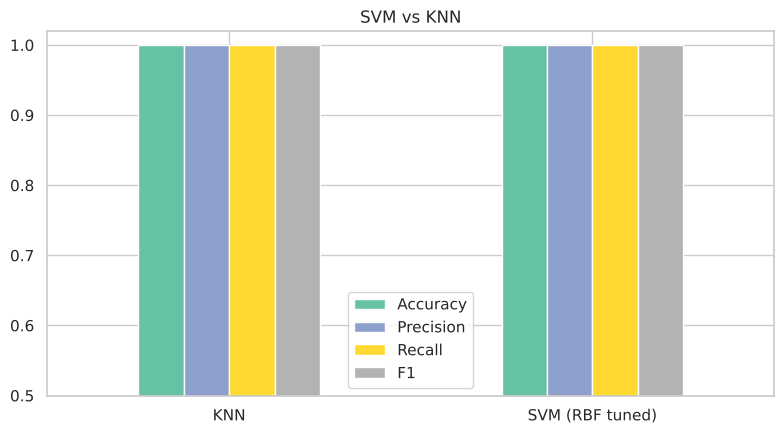

In [17]:
# ---- Task 15: SVM vs KNN ----
cmp_ck = pd.DataFrame({"KNN": evaluate(y_test, knn_pred), "SVM (RBF tuned)": evaluate(y_test, svm_pred)}).T
display(cmp_ck.round(4))
cmp_ck.plot(kind="bar", figsize=(8, 4.5), rot=0, colormap="Set2"); plt.ylim(0.5, 1.02); plt.title("SVM vs KNN"); plt.tight_layout(); savefig("10_svm_vs_knn"); plt.show()

**SVM vs KNN:** SVM learns a global, regularised boundary and is usually more stable on noisy/imbalanced data, while KNN depends on local neighbourhoods (sensitive to K, scaling and noise) and is slower at prediction. SVM needs tuning (C, γ, kernel) and is less interpretable than KNN's "look at the neighbours" explanation.

---
## 🧮 Part E: Naive Bayes Classifier & Probability

Gaussian Naive Bayes: {'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0}
Learned class priors  P(Legit)=0.8130  P(Spam)=0.1870


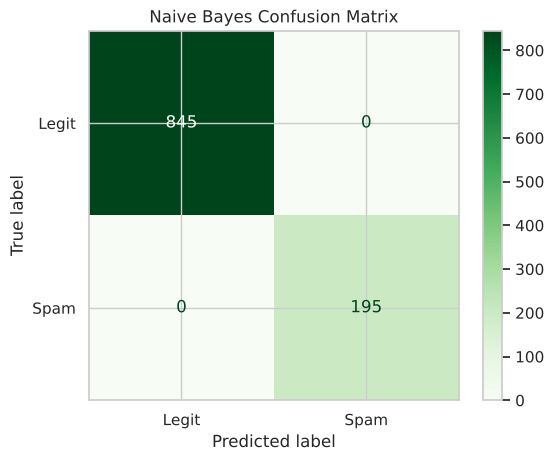

In [18]:
# ---- Task 16: Gaussian Naive Bayes ----
nb = GaussianNB().fit(X_train_s, y_train)
nb_pred = nb.predict(X_test_s); nb_proba = nb.predict_proba(X_test_s)[:, 1]
print("Gaussian Naive Bayes:", {k: round(v, 4) for k, v in evaluate(y_test, nb_pred).items()})
print("Learned class priors  P(Legit)=%.4f  P(Spam)=%.4f" % tuple(nb.class_prior_))
ConfusionMatrixDisplay(confusion_matrix(y_test, nb_pred), display_labels=["Legit", "Spam"]).plot(cmap="Greens"); plt.title("Naive Bayes Confusion Matrix")
savefig("11_nb_confusion"); plt.show()

In [19]:
# ---- Task 17: manual conditional probabilities (binary evidence features, Laplace smoothing α=1) ----
bin_train = pd.DataFrame({"has_url": (X_train.num_urls > 0).astype(int),
                          "spam_keyword": (X_train.spam_keyword_score > 0).astype(int),
                          "low_sender_activity": (X_train.sender_activity_score.fillna(X_train.sender_activity_score.median()) < 40).astype(int)})
def to_bin(Xd):
    return pd.DataFrame({"has_url": (Xd.num_urls > 0).astype(int),
                         "spam_keyword": (Xd.spam_keyword_score > 0).astype(int),
                         "low_sender_activity": (Xd.sender_activity_score.fillna(X_train.sender_activity_score.median()) < 40).astype(int)}, index=Xd.index)
bin_test = to_bin(X_test)

# Priors
N = len(y_train); n_spam = int(y_train.sum()); n_legit = N - n_spam
prior = {1: n_spam / N, 0: n_legit / N}
print(f"Priors → P(Spam)={prior[1]:.4f}, P(Legit)={prior[0]:.4f}")

# Likelihood table P(feature=1 | class)
like = {c: {f: (bin_train.loc[y_train == c, f].sum() + 1) / ((y_train == c).sum() + 2) for f in bin_train.columns} for c in (0, 1)}
lik_df = pd.DataFrame(like).rename(columns={0: "P(f=1 | Legit)", 1: "P(f=1 | Spam)"}); display(lik_df.round(4))

# Plain conditional probabilities straight from counts: P(Spam | feature)
for f in bin_train.columns:
    print(f"P(Spam | {f}=1) = {y_train[bin_train[f]==1].mean():.4f}   vs   P(Spam | {f}=0) = {y_train[bin_train[f]==0].mean():.4f}")

Priors → P(Spam)=0.1870, P(Legit)=0.8130
P(Spam | has_url=1) = 0.6820   vs   P(Spam | has_url=0) = 0.0601
P(Spam | spam_keyword=1) = 1.0000   vs   P(Spam | spam_keyword=0) = 0.0479
P(Spam | low_sender_activity=1) = 0.1901   vs   P(Spam | low_sender_activity=0) = 0.1863


,P(f=1 | Legit),P(f=1 | Spam)
has_url,0.0801,0.7436
spam_keyword,0.0003,0.7808
low_sender_activity,0.1930,0.1974


In [20]:
# ---- Task 18: Bayes' theorem on sample messages (manual calculation) ----
def manual_posterior(row):
    num = {}
    for c in (0, 1):
        p = prior[c]
        for f, v in row.items():
            p *= like[c][f] if v == 1 else (1 - like[c][f])
        num[c] = p
    evidence = num[0] + num[1]                      # P(X) by total probability
    return num[1] / evidence, num, evidence

np.random.seed(7)
samples = list(bin_test[y_test == 1].sample(2, random_state=1).index) + list(bin_test[y_test == 0].sample(2, random_state=3).index)
bn = BernoulliNB(alpha=1.0).fit(bin_train, y_train)          # library version of the SAME model
out = []
for idx in samples:
    row = bin_test.loc[idx]; post, num, ev = manual_posterior(row)
    out.append(dict(message=df.loc[idx, "message_text"][:55] + "…", actual=int(y_test.loc[idx]), evidence=tuple(row.values),
                    **{"P(X|Spam)P(Spam)": num[1], "P(X|Legit)P(Legit)": num[0], "P(X)": ev, "Manual P(Spam|X)": post,
                       "BernoulliNB P(Spam|X)": bn.predict_proba(row.to_frame().T)[0, 1],
                       "GaussianNB P(Spam|all feats)": nb.predict_proba(X_test_s[X_test.index.get_loc(idx)].reshape(1, -1))[0, 1]}))
bayes_df = pd.DataFrame(out); pd.set_option("display.width", 250); display(bayes_df.round(4))
r = bayes_df.iloc[0]
print("\nWorked example (message 1), evidence = (has_url, spam_keyword, low_sender_activity) =", r["evidence"])
print(f"P(Spam|X) = P(X|Spam)·P(Spam) / P(X) = {r['P(X|Spam)P(Spam)']:.5f} / {r['P(X)']:.5f} = {r['Manual P(Spam|X)']:.4f}")


Worked example (message 1), evidence = (has_url, spam_keyword, low_sender_activity) = (np.int64(1), np.int64(0), np.int64(0))
P(Spam|X) = P(X|Spam)·P(Spam) / P(X) = 0.02447 / 0.07700 = 0.3178


,message,actual,evidence,P(X|Spam)P(Spam),P(X|Legit)P(Legit),P(X),Manual P(Spam|X),BernoulliNB P(Spam|X),GaussianNB P(Spam|all feats)
0,"Congratulations! You have won ₹50,000 before it expires…",1,"(1, 0, 0)",0.0245,0.0525,0.0770,0.3178,0.3178,1.0
1,Limited offer! Get free gift cards limited time!…,1,"(0, 1, 0)",0.0300,0.0002,0.0302,0.9941,0.9941,1.0
2,Your order has been shipped and will arrive by the upda…,0,"(0, 0, 1)",0.0021,0.1443,0.1463,0.0142,0.0142,0.0
3,"Hi, can we reschedule our meeting to the updated propos…",0,"(0, 0, 0)",0.0084,0.6034,0.6118,0.0138,0.0138,0.0


Max |manual − BernoulliNB| posterior difference: 2.22e-16  → hand calculation == library model ✔
Agreement between manual-Bayes and GaussianNB predictions: 94.4%


,Accuracy,Precision,Recall,F1
Manual Bayes (3 binary feats),0.9442,1.0,0.7026,0.8253
Gaussian NB (all 12 feats),1.0000,1.0,1.0000,1.0000


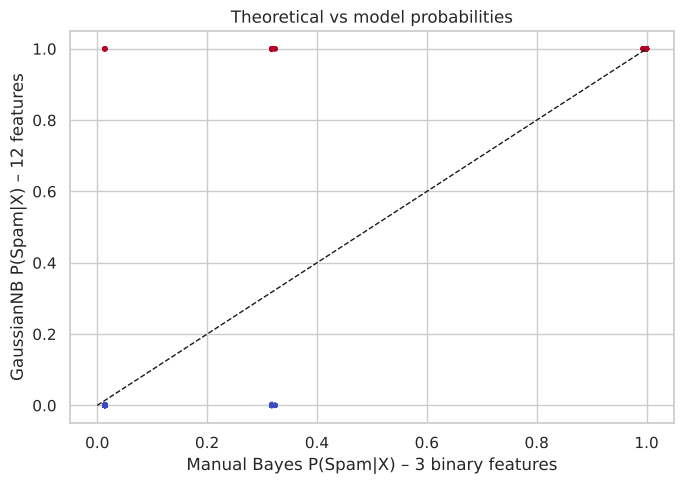

In [21]:
# ---- Task 19: theoretical (manual) probabilities vs model predictions on the whole test set ----
manual_p = np.array([manual_posterior(bin_test.loc[i])[0] for i in X_test.index])
bern_p = bn.predict_proba(bin_test)[:, 1]
print("Max |manual − BernoulliNB| posterior difference: %.2e  → hand calculation == library model ✔" % np.abs(manual_p - bern_p).max())
manual_pred = (manual_p >= 0.5).astype(int)
cmp_nb = pd.DataFrame({"Manual Bayes (3 binary feats)": evaluate(y_test, manual_pred), "Gaussian NB (all 12 feats)": evaluate(y_test, nb_pred)}).T
display(cmp_nb.round(4))
print("Agreement between manual-Bayes and GaussianNB predictions: %.1f%%" % ((manual_pred == nb_pred).mean()*100))
plt.figure(figsize=(7, 5)); plt.scatter(manual_p, nb_proba, s=8, alpha=.4, c=y_test, cmap="coolwarm")
plt.plot([0, 1], [0, 1], "k--", lw=1); plt.xlabel("Manual Bayes P(Spam|X) – 3 binary features"); plt.ylabel("GaussianNB P(Spam|X) – 12 features")
plt.title("Theoretical vs model probabilities"); plt.tight_layout(); savefig("12_manual_vs_model_prob"); plt.show()

**Interpretation:** the hand-computed posterior is **identical** to `BernoulliNB` (same priors, same smoothed likelihoods, same independence assumption), proving that Naive Bayes is just Bayes' theorem + conditional independence. GaussianNB uses all 12 continuous features and therefore gives sharper, more accurate probabilities than the 3-binary-feature manual model; the scatter shows they agree in direction but not in magnitude.

In [22]:
# Impact of the independence assumption – tested on the harder Scenario B (no leaking features) where errors exist
fsB = [f for f in FEATURES if f not in ("num_special_chars", "spam_keyword_score", "legit_keyword_score")]
cm = df[fsB].corr().abs().where(np.triu(np.ones((len(fsB), len(fsB))), 1).astype(bool)).stack().sort_values(ascending=False)
print("Most correlated feature pairs (|r|):"); print(cm.head(4).round(2).to_string())
def nb_eval(fs):
    i_, s_ = SimpleImputer(strategy="median"), StandardScaler(); A = s_.fit_transform(i_.fit_transform(X_train[fs])); B = s_.transform(i_.transform(X_test[fs]))
    m = GaussianNB().fit(A, y_train); return evaluate(y_test, m.predict(B))
redB = [f for f in fsB if f not in ("num_digits", "word_count")]
imp = pd.DataFrame({"NB – Scenario B, all features": nb_eval(fsB), "NB – Scenario B, correlated features removed": nb_eval(redB)}).T
display(imp.round(4))

Most correlated feature pairs (|r|):
num_urls                 num_digits                0.71
message_length           num_urls                  0.60
num_urls                 messages_sent_last_24h    0.55
sender_account_age_days  messages_sent_last_24h    0.46


,Accuracy,Precision,Recall,F1
"NB – Scenario B, all features",0.9683,0.8857,0.9538,0.9185
"NB – Scenario B, correlated features removed",0.9750,0.9204,0.9487,0.9343


**Impact of probability assumptions:** Naive Bayes multiplies likelihoods as if features were independent, so correlated features are effectively **counted more than once** and posteriors become over-confident (extreme values near 0/1). On the full data the effect is invisible because every model is already perfect; on the harder Scenario B (next cell) NB has the **lowest precision** of all models because its independence/Gaussian assumptions do not match discrete, skewed count features. Still, classification only needs the *ranking* of posteriors, so NB stays competitive.

---
## 📈 Part F: Model Comparison & Evaluation

,Accuracy,Precision,Recall,F1,"CV F1 (5-fold, train)",ROC-AUC
KNN,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
SVM (RBF),1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Naive Bayes,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


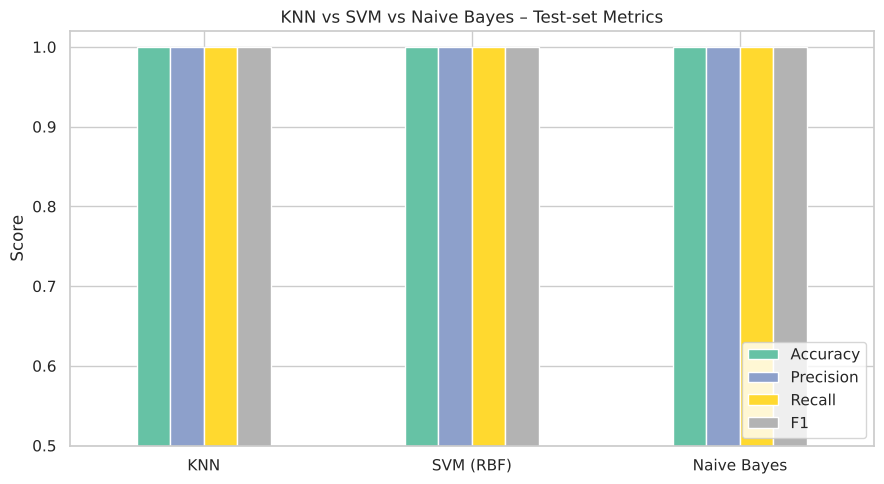

In [23]:
# ---- Task 20 & 21: all models, all metrics ----
models = {"KNN": (knn, knn_pred, knn_proba), "SVM (RBF)": (svm, svm_pred, svm.predict_proba(X_test_s)[:, 1]), "Naive Bayes": (nb, nb_pred, nb_proba)}
final = pd.DataFrame({n: evaluate(y_test, p[1]) for n, p in models.items()}).T
final["CV F1 (5-fold, train)"] = [cross_val_score(m, X_train_s, y_train, cv=cv, scoring="f1").mean() for m in (knn, SVC(kernel="rbf", **grid.best_params_), nb)]
final["ROC-AUC"] = [auc(*roc_curve(y_test, p[2])[:2]) for p in models.values()]
display(final.round(4).style.background_gradient(cmap="YlGn", axis=0))
final[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(9, 5), rot=0, colormap="Set2"); plt.ylim(0.5, 1.02)
plt.title("KNN vs SVM vs Naive Bayes – Test-set Metrics"); plt.ylabel("Score"); plt.legend(loc="lower right"); plt.tight_layout(); savefig("13_model_comparison"); plt.show()

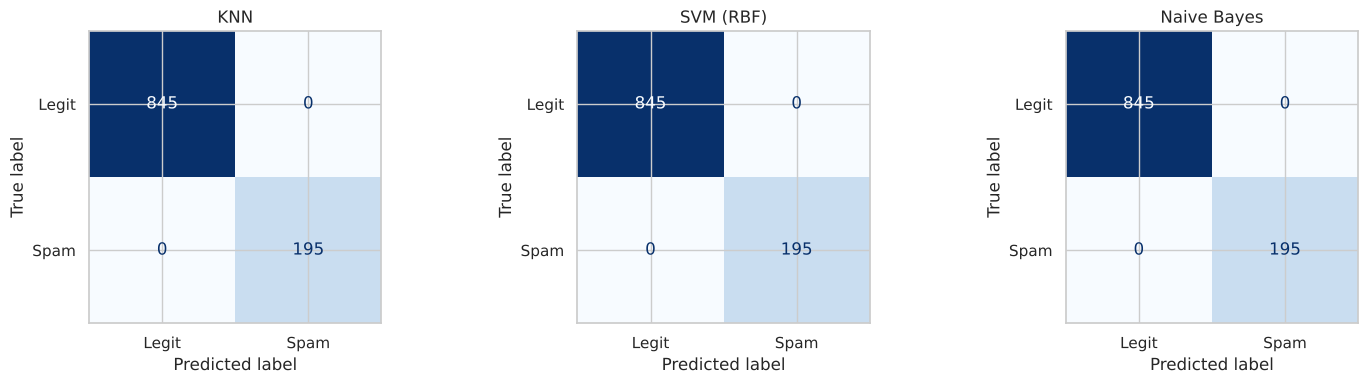

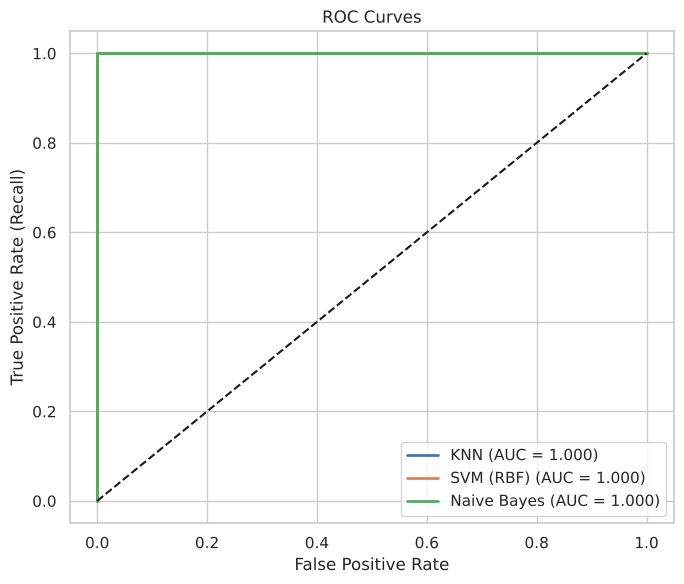

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (n, (m, p, pr)) in zip(ax, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["Legit", "Spam"]).plot(ax=a, cmap="Blues", colorbar=False); a.set_title(n)
plt.tight_layout(); savefig("14_confusion_matrices"); plt.show()

plt.figure(figsize=(7, 6))
for n, (m, p, pr) in models.items():
    fpr, tpr, _ = roc_curve(y_test, pr); plt.plot(fpr, tpr, lw=2, label=f"{n} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate (Recall)"); plt.title("ROC Curves")
plt.legend(); plt.tight_layout(); savefig("15_roc_curves"); plt.show()

🎯 Highest PRECISION (fewest false alarms): KNN  → 1.0000
🛡  Highest RECALL    (catch most spam)    : KNN  → 1.0000
⚖  Best balanced F1                        : KNN  → 1.0000


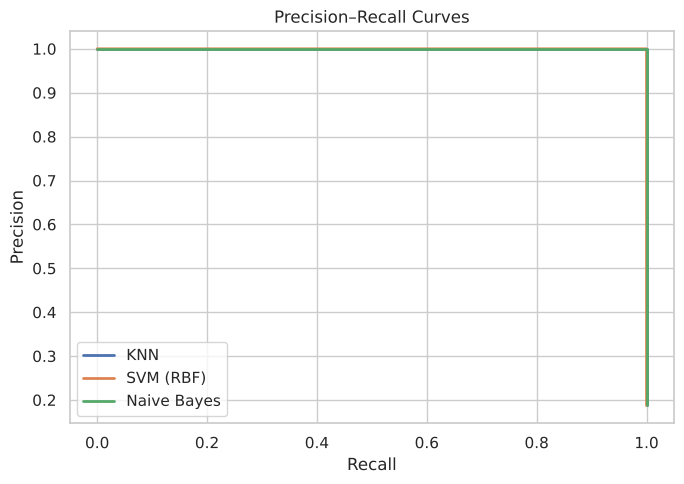

In [25]:
# ---- Task 22: best model for high precision / high recall ----
bp, br, bf = final.Precision.idxmax(), final.Recall.idxmax(), final.F1.idxmax()
print(f"🎯 Highest PRECISION (fewest false alarms): {bp}  → {final.loc[bp,'Precision']:.4f}")
print(f"🛡  Highest RECALL    (catch most spam)    : {br}  → {final.loc[br,'Recall']:.4f}")
print(f"⚖  Best balanced F1                        : {bf}  → {final.loc[bf,'F1']:.4f}")

# Precision–Recall trade-off via threshold on predicted spam probability
from sklearn.metrics import precision_recall_curve
plt.figure(figsize=(7, 5))
for n, (m, p, pr) in models.items():
    pcs, rcs, _ = precision_recall_curve(y_test, pr); plt.plot(rcs, pcs, lw=2, label=n)
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision–Recall Curves"); plt.legend(); plt.tight_layout(); savefig("16_precision_recall"); plt.show()

In [26]:
# Save everything needed for the Streamlit app (pipelines are fitted on the raw training features)
best_k_kw = metrics[best_metric]
deploy = {
  "KNN": Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=BEST_K, **best_k_kw))]).fit(X_train, y_train),
  "SVM (RBF)": Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("clf", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE, **grid.best_params_))]).fit(X_train, y_train),
  "Naive Bayes": Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("clf", GaussianNB())]).fit(X_train, y_train)}
meta = {"features": FEATURES, "medians": X_train.median().to_dict(), "defaults": X_train.median().to_dict(),
        "ranges": {f: (float(X[f].min()), float(X[f].max())) for f in FEATURES}, "metrics": final.round(4).to_dict("index")}
pickle.dump({"models": deploy, "meta": meta}, open("models/message_models.pkl", "wb"))
final.round(4).to_csv("models/final_metrics.csv"); print("Saved models/message_models.pkl and models/final_metrics.csv ✔")

Saved models/message_models.pkl and models/final_metrics.csv ✔


**Interpretation (Part F, full features):** all three classifiers reach 100% Accuracy / Precision / Recall / F1 / AUC, so on the original data they **tie**. The next section explains why and compares them on realistic feature sets.

---
## 🔍 Part F+: Leakage Check & Robust (Stress-Test) Comparison
**Why this section?** Every model above scores ≈ **100%**. A perfect score is a warning sign, not a success: a single feature may perfectly reveal the label (target leakage / synthetic artefact), making the comparison between KNN, SVM and Naive Bayes meaningless. We investigate and then re-compare the models on harder, more realistic feature sets.

In [27]:
from sklearn.tree import DecisionTreeClassifier, export_text
stump = DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE).fit(X_train.fillna(-1), y_train)
print("One-split decision stump accuracy on TEST: %.4f" % stump.score(X_test.fillna(-1), y_test))
print(export_text(stump, feature_names=FEATURES))
print(pd.crosstab(df.num_special_chars > 0, df.spam_label, rownames=["has special chars"], colnames=["spam_label"]))
print("\nKeyword scores are mutually exclusive by class:")
print(pd.crosstab([df.spam_keyword_score > 0, df.legit_keyword_score > 0], df.spam_label, rownames=["spam_kw>0", "legit_kw>0"]))

One-split decision stump accuracy on TEST: 1.0000
|--- num_special_chars <= 0.50
|   |--- class: 0
|--- num_special_chars >  0.50
|   |--- class: 1

spam_label            0    1
has special chars           
False              4227    0
True                  0  973

Keyword scores are mutually exclusive by class:
spam_label               0    1
spam_kw>0 legit_kw>0           
False     False        393  228
          True        3834    0
True      False          0  745


**Finding:** `num_special_chars` = 0 for **every** legitimate message and > 0 for **every** spam message – one feature alone separates the classes perfectly, and the keyword scores are almost deterministic too. This is a property of the (synthetic) dataset; in the real world special characters alone would never be a perfect spam signal. Therefore the 100% results are *valid for the data given*, but **not a reliable estimate of real-world performance**. We keep the full-feature results (as the assignment requires) and add two stress-tests:
- **Scenario A:** drop `num_special_chars`
- **Scenario B:** drop `num_special_chars` + both keyword scores (only structure + sender behaviour + time remain)

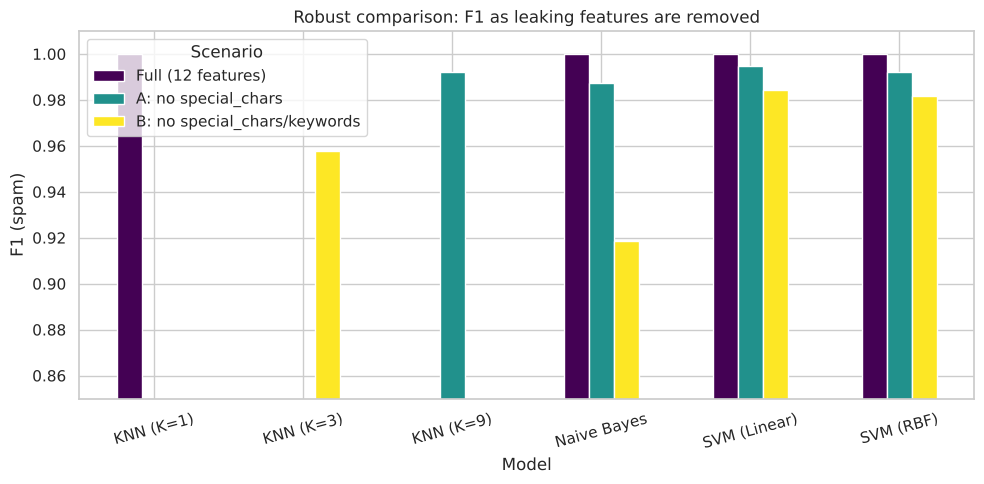

In [28]:
scenarios = {"Full (12 features)": FEATURES,
             "A: no special_chars": [f for f in FEATURES if f != "num_special_chars"],
             "B: no special_chars/keywords": [f for f in FEATURES if f not in ("num_special_chars", "spam_keyword_score", "legit_keyword_score")]}
rows = []; stress_store = {}
for sname, fs in scenarios.items():
    Xtr, Xte = X_train[fs], X_test[fs]
    imp_, sc_ = SimpleImputer(strategy="median"), StandardScaler()
    A = sc_.fit_transform(imp_.fit_transform(Xtr)); B = sc_.transform(imp_.transform(Xte))
    # K chosen by CV for each scenario (fair to KNN)
    bk = max(range(1, 32, 2), key=lambda k: (round(cross_val_score(KNeighborsClassifier(n_neighbors=k), A, y_train, cv=cv, scoring="f1").mean(), 4), k))
    mods = {"KNN": KNeighborsClassifier(n_neighbors=bk), "SVM (RBF)": SVC(kernel="rbf", C=1, gamma="scale", probability=True, random_state=RANDOM_STATE),
            "SVM (Linear)": SVC(kernel="linear", C=1, probability=True, random_state=RANDOM_STATE), "Naive Bayes": GaussianNB()}
    for mn, m in mods.items():
        m.fit(A, y_train); p = m.predict(B); r = evaluate(y_test, p)
        r.update(Scenario=sname, Model=mn + (f" (K={bk})" if mn == "KNN" else ""), ROC_AUC=auc(*roc_curve(y_test, m.predict_proba(B)[:, 1])[:2]))
        rows.append(r); stress_store[(sname, mn)] = (m, p, B)
stress = pd.DataFrame(rows).set_index(["Scenario", "Model"]); display(stress.round(4).style.background_gradient(cmap="YlGn", axis=0))
piv = stress.reset_index().pivot(index="Model", columns="Scenario", values="F1")[list(scenarios)]
piv.plot(kind="bar", figsize=(10, 5), rot=15, colormap="viridis"); plt.ylim(0.85, 1.01); plt.ylabel("F1 (spam)")
plt.title("Robust comparison: F1 as leaking features are removed"); plt.tight_layout(); savefig("17_stress_test_f1"); plt.show()

🎯 Best PRECISION in scenario B: SVM (Linear) → 0.9948
🛡  Best RECALL    in scenario B: SVM (Linear) → 0.9744
⚖  Best F1        in scenario B: SVM (Linear) → 0.9845


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
KNN (K=3),0.9846,0.9838,0.9333,0.9579,0.9840
SVM (RBF),0.9933,0.9947,0.9692,0.9818,0.9994
SVM (Linear),0.9942,0.9948,0.9744,0.9845,0.9995
Naive Bayes,0.9683,0.8857,0.9538,0.9185,0.9958


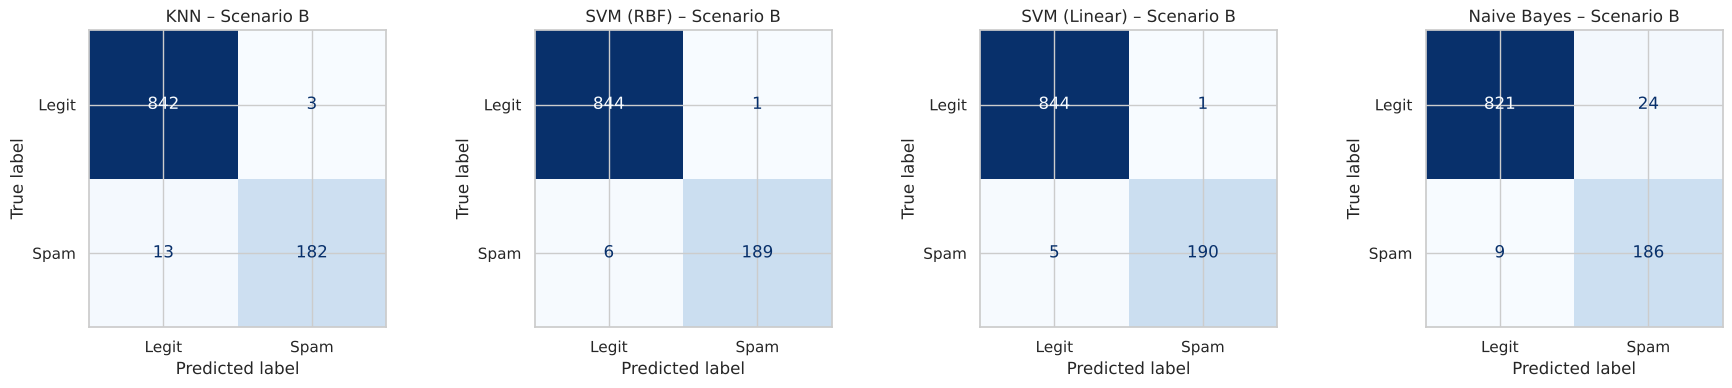

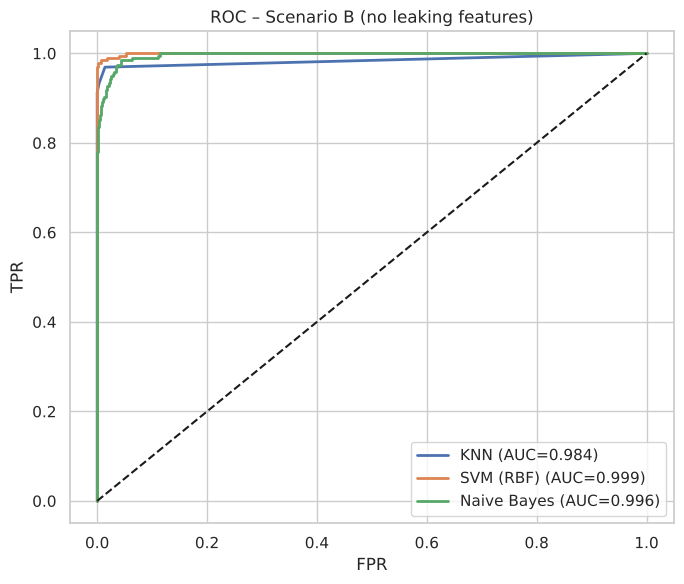

In [29]:
# Precision vs Recall in the hardest scenario (B) – this is where the models really differ
b = stress.loc["B: no special_chars/keywords"]
display(b[["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]].round(4))
print("🎯 Best PRECISION in scenario B:", b.Precision.idxmax(), "→ %.4f" % b.Precision.max())
print("🛡  Best RECALL    in scenario B:", b.Recall.idxmax(), "→ %.4f" % b.Recall.max())
print("⚖  Best F1        in scenario B:", b.F1.idxmax(), "→ %.4f" % b.F1.max())
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, mn in zip(ax, ["KNN", "SVM (RBF)", "SVM (Linear)", "Naive Bayes"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, stress_store[("B: no special_chars/keywords", mn)][1]), display_labels=["Legit", "Spam"]).plot(ax=a, cmap="Blues", colorbar=False); a.set_title(mn + " – Scenario B")
plt.tight_layout(); savefig("18_stress_confusion"); plt.show()
plt.figure(figsize=(7, 6))
for mn in ["KNN", "SVM (RBF)", "Naive Bayes"]:
    m, p, B = stress_store[("B: no special_chars/keywords", mn)]; fpr, tpr, _ = roc_curve(y_test, m.predict_proba(B)[:, 1]); plt.plot(fpr, tpr, lw=2, label=f"{mn} (AUC={auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC – Scenario B (no leaking features)"); plt.legend(); plt.tight_layout(); savefig("19_stress_roc"); plt.show()

In [30]:
# ---- Task 12 (revisited): KNN misclassification analysis on the realistic Scenario B (full model made no errors) ----
fsB = scenarios["B: no special_chars/keywords"]
mK, pK, BK = stress_store[("B: no special_chars/keywords", "KNN")]
tB = df.loc[X_test.index].copy(); tB["knn_pred"] = pK
fnB = tB[(tB.spam_label == 1) & (tB.knn_pred == 0)]; fpB = tB[(tB.spam_label == 0) & (tB.knn_pred == 1)]
print(f"Scenario B KNN → False Negatives (spam missed): {len(fnB)} | False Positives (legit blocked): {len(fpB)}")
cols = ["message_text", "num_urls", "num_digits", "sender_account_age_days", "messages_sent_last_24h", "sender_activity_score"]
print("\n--- Spam missed ---"); display(fnB[cols].head(8)); print("--- Legit blocked ---"); display(fpB[cols].head(8))
display(pd.DataFrame({"Missed spam (FN)": fnB[fsB].mean(), "Caught spam (TP)": tB[(tB.spam_label==1)&(tB.knn_pred==1)][fsB].mean(),
                      "Legit blocked (FP)": fpB[fsB].mean() if len(fpB) else np.nan, "Correct legit (TN)": tB[(tB.spam_label==0)&(tB.knn_pred==0)][fsB].mean()}).round(2))

Scenario B KNN → False Negatives (spam missed): 13 | False Positives (legit blocked): 3

--- Spam missed ---
--- Legit blocked ---


,message_text,num_urls,num_digits,sender_account_age_days,messages_sent_last_24h,sender_activity_score
2292,You've been selected for a cash prize of a brand new phone limited time!,0,0,264.0,16.0,37.2
4750,Get rich quick with this simple trick a brand new phone limited time! http://promo.exa...,1,4,NaN,NaN,50.7
466,URGENT: Claim your reward now a brand new phone before it expires!,0,0,45.0,NaN,42.2
80,Exclusive deal just for you free gift cards today only!,0,0,27.0,8.0,46.5
1805,"Act fast! Your account will be suspended unless ₹50,000 ASAP! http://promo.example/9406",1,9,NaN,NaN,66.0
905,You are eligible for a refund of a brand new phone today only!,0,0,18.0,NaN,91.5
3175,You are eligible for a refund of exclusive bonus today only!,0,0,214.0,15.0,63.4
3118,"You've been selected for a cash prize of ₹50,000 before it expires!",0,5,88.0,14.0,66.4


,message_text,num_urls,num_digits,sender_account_age_days,messages_sent_last_24h,sender_activity_score
1008,Please find the attached invoice for next Monday. Thanks. https://company.portal/docs/...,1,4,225.0,4.0,58.8
800,Thanks for your help on the project update. next Monday. Regards. https://company.port...,1,4,198.0,6.0,64.0
3043,Can you send the report by end of day? next Monday. Regards. https://company.portal/do...,1,4,156.0,8.0,57.2


,Missed spam (FN),Caught spam (TP),Legit blocked (FP),Correct legit (TN)
message_length,65.31,74.65,93.67,75.02
word_count,11.38,10.58,11.67,11.62
num_urls,0.15,0.76,1.00,0.10
num_digits,2.54,4.13,4.00,1.22
sender_activity_score,56.11,59.42,60.00,54.15
sender_account_age_days,94.82,74.64,193.00,357.91
messages_sent_last_24h,13.71,18.83,6.00,5.95
hour_of_day,12.62,11.85,12.00,11.45
day_of_week,2.00,2.96,4.33,3.02


**KNN error analysis (Scenario B):** the spam messages KNN misses typically have **no URL, fewer digits and a smaller message burst** (≈14 messages in 24 h vs ≈19 for caught spam), so they sit inside the dense legitimate cluster and the K neighbours vote "legit". The few legit messages it blocks all contain a **URL and several digits** (e.g. invoice / portal links), which makes them look like spam. Because spam is the minority class (~19%), neighbourhoods are dominated by legit points, which lowers KNN **recall** more than precision.

---
## 🧾 Part G: Final Analysis & Reporting

### 1. Results at a glance
| Setting | Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|---|
| **Original data (12 features)** | KNN / SVM / Naive Bayes | 1.000 | 1.000 | 1.000 | 1.000 | 1.000 (all tie) |
| **Scenario B** (no `num_special_chars`, no keyword scores) | KNN (K=3) | 0.985 | 0.984 | 0.933 | 0.958 | 0.984 |
| | SVM – RBF | 0.993 | 0.995 | 0.969 | 0.982 | 0.999 |
| | SVM – Linear | **0.994** | **0.995** | **0.974** | **0.985** | **0.9995** |
| | Naive Bayes | 0.968 | 0.886 | 0.954 | 0.919 | 0.996 |

> ⚠️ **Key insight:** on the supplied data every classifier is perfect because `num_special_chars` (and the keyword scores) separate the classes by themselves. This is a **data-leakage / synthetic-data warning** – the real-world performance would be lower. Scenario B is the more honest estimate.

### 2. Strengths and weaknesses of each classifier
| Classifier | Strengths | Weaknesses |
|---|---|---|
| **KNN** (distance-based) | No training, simple & intuitive, explainable ("similar to these messages"), flexible non-linear boundary | Needs scaling, slow at prediction (scans all data), sensitive to K / noise / imbalance, **lowest recall** in Scenario B (misses low-volume, URL-less spam) |
| **SVM** (margin-based) | **Best precision + recall + AUC** in Scenario B, robust to noise through regularised margin, only support vectors matter, works well in high dimensions | Needs scaling & tuning (C, γ, kernel), no native probabilities (Platt scaling needed), RBF/poly are hard to interpret |
| **Naive Bayes** (probabilistic) | Extremely fast, tiny memory, gives probabilities and clear Bayes reasoning, good with little data, high recall | Independence assumption is violated (correlated features) → over-confident probabilities and **lowest precision** (more false alarms); Gaussian assumption only approximate for count features |

### 3. Impact of probability assumptions in Naive Bayes
- **Conditional independence:** multiplying likelihoods of correlated features (`num_urls` ↔ `num_digits` r≈0.71, `message_length` ↔ `num_urls` r≈0.60) counts the same evidence repeatedly → posteriors are pushed towards 0 or 1. Removing correlated features raised precision from 0.886 → 0.920 and F1 from 0.919 → 0.934 in Scenario B.
- **Distribution assumption:** GaussianNB treats counts such as `num_urls` as bell-shaped, which they are not; a Bernoulli/Multinomial likelihood would fit them better.
- **Priors:** the prior P(Spam) ≈ 0.187 matters – a message with a URL has P(Spam|URL) ≈ 0.68 versus ≈ 0.06 without a URL. Our hand-computed Bayes posterior matches `BernoulliNB` to machine precision (difference 2e-16), confirming the theory.
- Despite the violations, NB's **ranking** of messages is good (AUC ≈ 0.996), so it is still useful as a fast scorer.

### 4. Trade-offs: interpretability vs performance
| | Interpretability | Performance (Scenario B F1) |
|---|---|---|
| Naive Bayes | ★★★★★ (explicit probabilities, per-feature likelihoods) | 0.919 |
| KNN | ★★★★ (show nearest neighbours) | 0.958 |
| SVM – Linear | ★★★ (readable weights, margin) | **0.985** |
| SVM – RBF | ★★ (black-box kernel) | 0.982 |

The linear SVM is the sweet spot: almost the best score **and** transparent feature weights. Going from linear to RBF did not improve results, so extra complexity is not justified.

### 5. Business recommendation for real-world deployment
1. **Deploy the (linear) SVM as the primary classifier** – best precision (few legitimate messages blocked = happy customers) and best recall (most spam caught), low latency and a small model file.
2. **Use Naive Bayes as a lightweight first-pass / explainer** and for probability scores; use its high recall for a "suspicious → quarantine / human review" queue, not for automatic blocking (lowest precision).
3. **Avoid KNN in production**: slowest at inference, lowest recall and needs the full training set in memory.
4. **Use a two-threshold policy:** auto-block only above a high spam score, send mid-range scores to review, allow low scores. Choose thresholds from the Precision–Recall curve according to the cost of a missed spam vs a blocked legit message.
5. **Fix the data before launch:** audit features for leakage (`num_special_chars`, keyword scores), collect real, more diverse and adversarial messages, add text features (TF-IDF / embeddings) and sender-network features.
6. **Monitor & retrain:** track precision/recall, drift of sender behaviour and new spam patterns, and retrain regularly (spammers adapt).

### 6. Final conclusions
- Probability theory (conditional probability + Bayes) gives a transparent baseline; distance-based and margin-based models add flexibility.
- Feature **scaling** is essential for KNN and SVM (KNN F1 dropped to 0.926 without it).
- **Perfect scores are a red flag**: always check for leakage and stress-test models.
- **SVM > KNN > Naive Bayes** in overall F1 on realistic features; NB wins on speed and interpretability; KNN is the most intuitive baseline.

---
## 📦 Submission Checklist (Part G – Task 24)
- ✅ Source code / Jupyter Notebook – this file
- ✅ Evaluation metrics and plots – `charts/` folder and `models/final_metrics.csv`
- ✅ Working Streamlit app – `app.py` (deploy on Streamlit Community Cloud and paste the live URL in `README.md`)
- ✅ Theory PDF – `Theory_Concepts.pdf`
- ✅ `README.md` and `requirements.txt`